# 03 — p5986 failure picks, TTF, and shear-stress labels


1. `ttf_to_failure_start_s`: time from the current mechanical sample to the next refined shear-stress peak;
2. `shear_stress_mpa`: source used to compute the mean shear stress inside each acoustic window.

Event detection is deliberately separate from acoustic features so the feature pipeline cannot leak mechanical labels.


In [ ]:
# ===== Common setup: Google Drive path and output folder =====
from pathlib import Path
import os, json, re, math, glob, shutil, warnings
import numpy as np
import pandas as pd

try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception as exc:
    print('Not running in Colab or Drive already mounted:', exc)

# Edit only when the Drive shortcut/folder is elsewhere.
P5986_ROOT = Path(os.environ.get(
    'P5986_ROOT',
    '/content/drive/MyDrive/MLStressDrop/p5986',
))
assert P5986_ROOT.exists(), (
    f'Cannot find p5986 folder: {P5986_ROOT}. '
    'Add a Drive shortcut or edit P5986_ROOT.'
)

MECH_DIR = P5986_ROOT / 'mechData'
AC_DIR = P5986_ROOT / 'acData'
RUN1_DIR = AC_DIR / 'run1'
MAT_DIR = AC_DIR / 'MatFiles'
OUT_DIR = P5986_ROOT / 'colab_outputs_p5986'
OUT_DIR.mkdir(exist_ok=True, parents=True)
print('P5986_ROOT =', P5986_ROOT)
print('OUT_DIR    =', OUT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
P5986_ROOT = /content/drive/MyDrive/MLStressDrop/p5986
OUT_DIR    = /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986


In [ ]:
# ===== Small HDF5 utilities =====
import h5py

def _as_array(x):
    x = np.asarray(x)
    if x.dtype == object:
        x = x.astype(str)
    return x

def save_dict_h5(path, data, attrs=None):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with h5py.File(path, 'w') as f:
        for k, v in data.items():
            arr = _as_array(v)
            if arr.dtype.kind in {'U', 'O'}:
                dt = h5py.string_dtype(encoding='utf-8')
                f.create_dataset(k, data=arr.astype(object), dtype=dt)
            else:
                f.create_dataset(k, data=arr, compression='gzip', compression_opts=4, shuffle=True)
        if attrs:
            for k, v in attrs.items():
                f.attrs[k] = json.dumps(v) if isinstance(v, (dict, list, tuple)) else v
    print('saved:', path)

def load_h5_to_dict(path):
    out = {}
    with h5py.File(path, 'r') as f:
        for k in f.keys():
            out[k] = f[k][()]
            if getattr(out[k], 'dtype', None) is not None and out[k].dtype.kind == 'S':
                out[k] = out[k].astype(str)
    return out

def load_h5_to_df(path):
    d = load_h5_to_dict(path)
    return pd.DataFrame({k: np.ravel(v) for k, v in d.items() if np.asarray(v).ndim <= 1})


## 1. Load calibrated mechanical data


In [ ]:
CAL_H5 = OUT_DIR / '02_mech_calibrated_p5986.h5'
assert CAL_H5.exists(), f'Run notebook 02 first: {CAL_H5}'

df = load_h5_to_df(CAL_H5)
required = {
    'time_s',
    'shear_stress_mpa',
    'normal_stress_mpa',
    'mu',
    'load_point_displacement_um',
    'sampfreq_hz',
    'loading_rate_um_s',
}
missing = required.difference(df.columns)
if missing:
    raise KeyError(f'Missing calibrated mechanical columns: {sorted(missing)}')

print('mechanical shape:', df.shape)
print('time range:', (df['time_s'].iloc[0], df['time_s'].iloc[-1]))
display(df[list(sorted(required))].head())


mechanical shape: (5673000, 19)
time range: (np.float64(1.0), np.float64(5700.000000702484))


,load_point_displacement_um,loading_rate_um_s,mu,normal_stress_mpa,sampfreq_hz,shear_stress_mpa,time_s
0,0.0,NaN,0.00000,0.000000e+00,1000.0,0.000000e+00,1.0
1,0.0,NaN,0.25578,8.932418e-09,1000.0,2.284731e-09,2.0
2,0.0,NaN,0.25578,1.786484e-08,1000.0,4.569461e-09,3.0
3,0.0,NaN,0.25578,2.679725e-08,1000.0,6.854192e-09,4.0
4,0.0,NaN,0.25578,3.572967e-08,1000.0,9.138922e-09,5.0


## 2. Conservative p5986 steady-run range and event-pick parameters

The runsheet gives acoustic start at record 1,044,000, shear command at 1,054,000, and unload at 4,957,000. The current p5986 preprocessing uses 2282999-3132999 as a conservative steady-analysis interval.


In [ ]:
from scipy import signal
import matplotlib.pyplot as plt

RUN1_IDX_BEG = 2_282_999
RUN1_IDX_END = 3_132_999
RUN1_IDX_BEG = max(0, RUN1_IDX_BEG)
RUN1_IDX_END = min(len(df), RUN1_IDX_END)

SMOOTH_WINDOW_S = 0.05
SMOOTH_POLY = 3
MIN_RECURRENCE_S = 1      # 最小復發週期 ：兩次地震發生的時間間隔不可能短於 1 秒
MIN_STRESS_DROP_MPA = 0.15   # 最小應力降 (0.15 MPa)：破裂後的應力掉落幅度必須大於此值
PROMINENCE_MPA = 0.15     # 峰值突出度 (0.15 MPa)：應力峰值必須比周圍的谷底高出至少才算數
MAX_TROUGH_SEARCH_S = 3    # 尋找應力谷底 (Trough) 的最大往前搜尋時間 (3秒)
NOMINAL_LOADING_RATE_UM_S = 10.0

# 根據上方定義的 Index 切出穩態資料
run = (
    df.iloc[RUN1_IDX_BEG:RUN1_IDX_END]
    .copy().reset_index(drop=False)       # 獨立複製一份，並重置 Index (保留原來的 Index 作為一個欄位)
    .rename(columns={'index': 'global_index'})  # 關鍵！將原本的絕對列號命名為 'global_index'
)
fs = float(np.nanmedian(run['sampfreq_hz']))
if not np.isfinite(fs) or fs <= 0:
    fs = 1000.0
tau = run['shear_stress_mpa'].to_numpy(dtype=np.float64)
time_s = run['time_s'].to_numpy(dtype=np.float64)
if not np.all(np.diff(time_s) > 0):
    raise ValueError('Mechanical time must be strictly increasing.')
print('run shape:', run.shape)
print('mechanical time:', (time_s[0], time_s[-1]), 'fs≈', fs, 'Hz')


run shape: (850000, 20)
mechanical time: (np.float64(2310.00000001185), np.float64(3159.9990001850174)) fs≈ 999.9999997962732 Hz


In [ ]:
# Smooth only for event picking.
win = int(round(SMOOTH_WINDOW_S * fs))
win = max(win, SMOOTH_POLY + 2)
if win % 2 == 0:
    win += 1
max_valid_win = len(tau) if len(tau) % 2 == 1 else len(tau) - 1
win = min(win, max_valid_win)
if win <= SMOOTH_POLY:
    raise ValueError('Savitzky-Golay window is too short.')

tau_smooth = signal.savgol_filter(
    tau,
    window_length=win,
    polyorder=SMOOTH_POLY,
    mode='interp',
)

prominence = PROMINENCE_MPA
if prominence is None:
    stress_range = (
        np.nanpercentile(tau_smooth, 95)
        - np.nanpercentile(tau_smooth, 5)
    )
    prominence = max(0.003, 0.03 * stress_range)

distance_samples = max(1, int(round(MIN_RECURRENCE_S * fs)))

candidate_peaks, peak_properties = signal.find_peaks(
    tau_smooth,
    prominence=prominence,
    distance=distance_samples,
)

print('smooth window samples:', win)
print('prominence:', prominence, 'MPa')
print('candidate peaks:', len(candidate_peaks))


smooth window samples: 51
prominence: 0.15 MPa
candidate peaks: 310


## 3. Create failure event catalog


In [ ]:
events = []

for j, peak_candidate in enumerate(candidate_peaks):
    next_peak_candidate = (
        candidate_peaks[j + 1]
        if j + 1 < len(candidate_peaks)
        else len(tau_smooth) - 1
    )

    max_search_end = min(
        len(tau_smooth) - 1,
        peak_candidate + int(round(MAX_TROUGH_SEARCH_S * fs)),
    )
    search_end = min(next_peak_candidate, max_search_end)

    if search_end <= peak_candidate + 2:
        continue

    trough_relative = int(
        np.nanargmin(tau_smooth[peak_candidate:search_end])
    )
    trough_candidate = peak_candidate + trough_relative

    # Refine extrema on original shear stress.
    refine_half_width = max(3, int(round(0.02 * fs)))

    peak_a = max(0, peak_candidate - refine_half_width)
    peak_b = min(len(tau), peak_candidate + refine_half_width + 1)
    peak_idx = peak_a + int(np.nanargmax(tau[peak_a:peak_b]))

    trough_a = max(peak_idx + 1, trough_candidate - refine_half_width)
    trough_b = min(len(tau), trough_candidate + refine_half_width + 1)
    if trough_b <= trough_a:
        continue
    trough_idx = trough_a + int(np.nanargmin(tau[trough_a:trough_b]))

    peak_stress = float(tau[peak_idx])
    trough_stress = float(tau[trough_idx])
    stress_drop = peak_stress - trough_stress

    if not np.isfinite(stress_drop) or stress_drop < MIN_STRESS_DROP_MPA:
        continue

    events.append({
        'event_id': len(events),
        'failure_global_index': int(run['global_index'].iloc[peak_idx]),
        'trough_global_index': int(run['global_index'].iloc[trough_idx]),
        'failure_local_index': int(peak_idx),
        'trough_local_index': int(trough_idx),
        'failure_time_s': float(time_s[peak_idx]),
        'peak_time_s': float(time_s[peak_idx]),  # compatibility alias
        'trough_time_s': float(time_s[trough_idx]),
        'peak_shear_stress_mpa': peak_stress,
        'trough_shear_stress_mpa': trough_stress,
        'stress_drop_mpa': float(stress_drop),
        'slip_duration_s': float(time_s[trough_idx] - time_s[peak_idx]),
        'normal_stress_at_failure_mpa':
            float(run['normal_stress_mpa'].iloc[peak_idx]),
        'friction_at_failure':
            float(run['mu'].iloc[peak_idx]),
        'lp_disp_at_failure_um':
            float(run['load_point_displacement_um'].iloc[peak_idx]),
        'loading_rate_at_failure_um_s':
            float(run['loading_rate_um_s'].iloc[peak_idx]),
    })

events_df = pd.DataFrame(events)

if events_df.empty:
    raise ValueError('No events were accepted. Check detection parameters.')

failure_times = events_df['failure_time_s'].to_numpy(dtype=np.float64)
if not np.all(np.diff(failure_times) > 0):
    raise ValueError('Failure picks are not strictly increasing.')

events_df['previous_failure_time_s'] = events_df['failure_time_s'].shift(1)
events_df['next_failure_time_s'] = events_df['failure_time_s'].shift(-1)
events_df['inter_event_time_from_previous_s'] = (
    events_df['failure_time_s'] - events_df['previous_failure_time_s']
)
events_df['cycle_duration_to_next_failure_s'] = (
    events_df['next_failure_time_s'] - events_df['failure_time_s']
)


# Compatibility aliases retained for older downstream notebooks.
events_df['peak_global_index'] = events_df['failure_global_index']
events_df['peak_local_index'] = events_df['failure_local_index']
events_df['normal_stress_at_peak_mpa'] = (
    events_df['normal_stress_at_failure_mpa']
)
events_df['friction_at_peak'] = events_df['friction_at_failure']
events_df['lp_disp_at_peak_um'] = events_df['lp_disp_at_failure_um']
events_df['loading_rate_at_peak_um_s'] = (
    events_df['loading_rate_at_failure_um_s']
)
events_df['recurrence_interval_s'] = (
    events_df['inter_event_time_from_previous_s']
)

print('accepted failure picks:', len(events_df))
display(events_df.head())


accepted failure picks: 310


,event_id,failure_global_index,trough_global_index,failure_local_index,trough_local_index,failure_time_s,peak_time_s,trough_time_s,peak_shear_stress_mpa,trough_shear_stress_mpa,...,next_failure_time_s,inter_event_time_from_previous_s,cycle_duration_to_next_failure_s,peak_global_index,peak_local_index,normal_stress_at_peak_mpa,friction_at_peak,lp_disp_at_peak_um,loading_rate_at_peak_um_s,recurrence_interval_s
0,0,2284510,2284698,1511,1699,2311.511,2311.511,2311.699,7.909523,7.375079,...,2314.244,NaN,2.733,2284510,1511,9.997672,0.791137,8481.366837,15.197266,NaN
1,1,2287243,2287507,4244,4508,2314.244,2314.244,2314.508,7.884158,7.492394,...,2316.844,2.733,2.600,2287243,4244,9.994634,0.788839,8510.027093,13.451546,2.733
2,2,2289843,2290173,6844,7174,2316.844,2316.844,2317.174,7.810294,7.563717,...,2318.661,2.600,1.817,2289843,6844,9.997917,0.781192,8536.679435,12.326080,2.600
3,3,2291660,2292150,8661,9151,2318.661,2318.661,2319.151,7.805482,7.458106,...,2321.276,1.817,2.615,2291660,8661,9.993377,0.781066,8555.696957,12.088313,1.817
4,4,2294275,2294530,11276,11531,2321.276,2321.276,2321.531,7.861776,7.333628,...,2324.859,2.615,3.583,2294275,11276,9.990598,0.786918,8581.050260,15.218458,2.615


## 4. Assign the single nominal p5986 loading-rate stage

The 10 μm/s value comes from the runsheet and is independently checked from DCDT in Notebook 02. It is metadata/QC, never an ML feature.


In [ ]:
events_df['loading_rate_stage_id'] = 'run1_10um_s'
events_df['nominal_loading_rate_um_s'] = NOMINAL_LOADING_RATE_UM_S
events_df['loading_rate_um_s'] = events_df['nominal_loading_rate_um_s']

print('failure picks in p5986 run1:', len(events_df))
print('measured DCDT-rate at failures (μm/s):')
display(events_df['loading_rate_at_failure_um_s'].describe())


failure picks in p5986 run1: 310
measured DCDT-rate at failures (μm/s):


,loading_rate_at_failure_um_s
count,310.000000
mean,13.818948
std,1.890599
min,7.843130
25%,12.751440
50%,14.036677
75%,15.215874
max,19.467596


## 5. 建立 continuous TTF 與 shear-stress label source

### TTF 定義

對 mechanical sample 時間 \(t\)：

\[
  \mathrm{TTF}(t)=t_{\mathrm{next\ failure\ start}}-t
\]

使用 `searchsorted(..., side="left")`，因此在 failure peak 的那個 sample：

- `TTF = 0`
- peak 之後的下一個 sample，目標會切換成下一次 event，形成論文中的 sawtooth label。

最後一個 failure 之後，因為 run1 範圍內已沒有可觀測的下一次 failure，
`TTF` 設為 `NaN`，之後不納入 supervised learning。

### Shear stress 定義

此處保存 1 kHz mechanical shear stress source。Notebook 05 不會只取 acoustic window
中央的一個 mechanical sample，而會計算 **相同 window 內的平均 shear stress**，
與 2019 論文標籤定義一致。


In [ ]:
next_failure_pos = np.searchsorted(
    failure_times,
    time_s,
    side='left',
)

valid_next_failure = next_failure_pos < len(failure_times)

ttf_s = np.full(len(time_s), np.nan, dtype=np.float64)
next_failure_time_s = np.full(len(time_s), np.nan, dtype=np.float64)
next_failure_event_id = np.full(len(time_s), -1, dtype=np.int64)

ttf_s[valid_next_failure] = (
    failure_times[next_failure_pos[valid_next_failure]]
    - time_s[valid_next_failure]
)
next_failure_time_s[valid_next_failure] = (
    failure_times[next_failure_pos[valid_next_failure]]
)
next_failure_event_id[valid_next_failure] = (
    next_failure_pos[valid_next_failure]
)

# Numerical guard.
tiny_negative = (ttf_s < 0) & (ttf_s > -1e-9)
ttf_s[tiny_negative] = 0.0

if np.nanmin(ttf_s) < 0:
    raise ValueError('TTF contains negative values.')


# ===== 建立同震區間標記 (Coseismic Flag) =====
is_coseismic = np.zeros(len(run), dtype=np.uint8)     # 初始化全為 0 的陣列
for row in events_df.itertuples(index=False):       # 遍歷我們在上一格抓出的合格地震事件
    a = int(row.failure_local_index)          # 取得破裂起點 (峰值) 的 Index
    b = int(row.trough_local_index)          # 取得破裂終點 (谷底) 的 Index
    is_coseismic[a:b + 1] = 1            # 將這段「正在掉落」的區間標記為 1 (True)

# ===== 組合最終標籤資料表 (Label DataFrame) =====
labels_df = pd.DataFrame({
    'global_index': run['global_index'].to_numpy(dtype=np.int64),
    'time_s': time_s,
    'shear_stress_mpa': tau,        # 連續的剪應力 (模型 B 的目標)
    'ttf_to_failure_start_s': ttf_s,    # 連續的 TTF (模型 A 的目標)
    'next_failure_time_s': next_failure_time_s,
    'next_failure_event_id': next_failure_event_id,
    'is_coseismic_peak_to_trough': is_coseismic,  # 遮罩標記
    'loading_rate_um_s':
        run['loading_rate_um_s'].to_numpy(dtype=np.float64),
})

print('label rows:', len(labels_df))
print('valid TTF rows:', labels_df['ttf_to_failure_start_s'].notna().sum())
print('TTF range:', (
    labels_df['ttf_to_failure_start_s'].min(),
    labels_df['ttf_to_failure_start_s'].max(),
))
display(labels_df.head())


label rows: 850000
valid TTF rows: 848737
TTF range: (0.0, 3.7860000007713097)


,global_index,time_s,shear_stress_mpa,ttf_to_failure_start_s,next_failure_time_s,next_failure_event_id,is_coseismic_peak_to_trough,loading_rate_um_s
0,2282999,2310.000,7.670027,1.511,2311.511,0,0,7.974548
1,2283000,2310.001,7.670264,1.510,2311.511,0,0,7.908626
2,2283001,2310.002,7.669719,1.509,2311.511,0,0,7.900432
3,2283002,2310.003,7.670714,1.508,2311.511,0,0,7.892239
4,2283003,2310.004,7.669689,1.507,2311.511,0,0,7.884045


## 6. QC: failure picks, TTF sawtooth, and single-rate cycle duration

The recommended 5%-cycle acoustic window is derived from all valid p5986 run1 inter-event intervals. Notebook 06 later repeats this using training cycles only to avoid feature-scale leakage.


same-stage cycle count: 309
mean cycle duration: 2.7418284795229853 s
median cycle duration: 2.7170000005535258 s
paper-style window ≈ 5% mean cycle: 0.13709142397614926 s


,nominal_loading_rate_um_s,n_cycles,mean_cycle_s,median_cycle_s,five_percent_mean_cycle_s
0,10.0,309,2.741828,2.717,0.137091


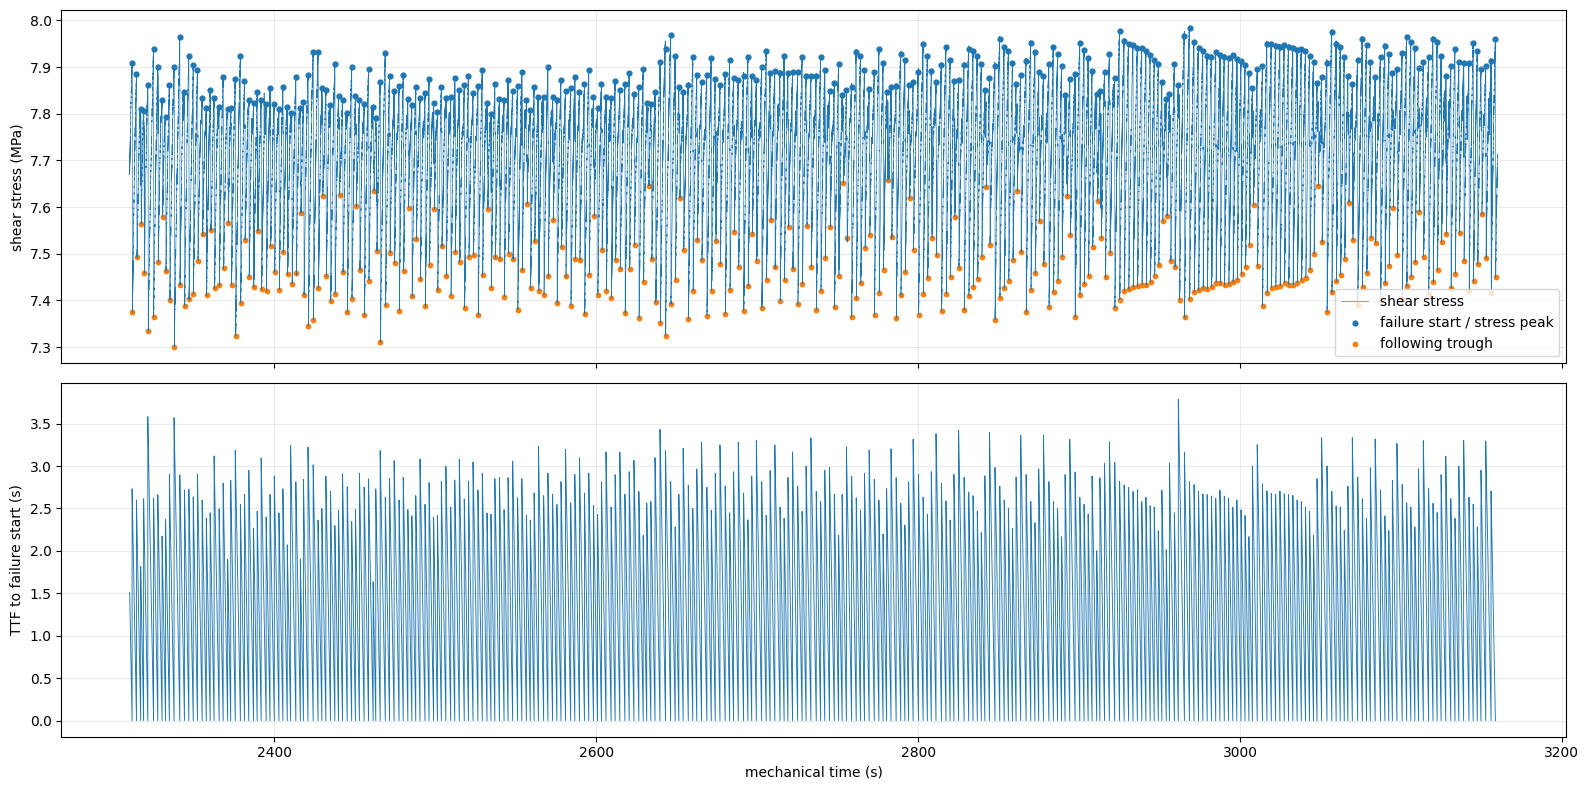

In [ ]:
# TTF must be exactly zero at accepted failure samples.
picked_ttf = labels_df.loc[
    events_df['failure_local_index'].to_numpy(dtype=int),
    'ttf_to_failure_start_s',
].to_numpy()

assert np.allclose(picked_ttf, 0.0, atol=1e-9), (
    'TTF is not zero at one or more failure picks.'
)

# Estimate the paper-style acoustic window length:
# approximately 5% of average recurrence interval.
event_rates = events_df['nominal_loading_rate_um_s'].to_numpy()
cycle_duration = events_df['cycle_duration_to_next_failure_s'].to_numpy()

same_rate_as_next = (
    np.isfinite(event_rates[:-1])
    & np.isfinite(event_rates[1:])
    & (event_rates[:-1] == event_rates[1:])
)

stable_cycle_duration = cycle_duration[:-1][same_rate_as_next]
stable_cycle_duration = stable_cycle_duration[
    np.isfinite(stable_cycle_duration)
    & (stable_cycle_duration > 0)
]

mean_cycle_s = float(np.mean(stable_cycle_duration))
median_cycle_s = float(np.median(stable_cycle_duration))
recommended_window_s = 0.05 * mean_cycle_s

print('same-stage cycle count:', len(stable_cycle_duration))
print('mean cycle duration:', mean_cycle_s, 's')
print('median cycle duration:', median_cycle_s, 's')
print('paper-style window ≈ 5% mean cycle:', recommended_window_s, 's')

rate_cycle_qc = []
for rate in sorted(events_df['nominal_loading_rate_um_s'].dropna().unique()):
    mask = (
        (events_df['nominal_loading_rate_um_s'].to_numpy()[:-1] == rate)
        & (events_df['nominal_loading_rate_um_s'].to_numpy()[1:] == rate)
    )
    vals = cycle_duration[:-1][mask]
    vals = vals[np.isfinite(vals) & (vals > 0)]
    if len(vals):
        rate_cycle_qc.append({
            'nominal_loading_rate_um_s': rate,
            'n_cycles': len(vals),
            'mean_cycle_s': np.mean(vals),
            'median_cycle_s': np.median(vals),
            'five_percent_mean_cycle_s': 0.05 * np.mean(vals),
        })

rate_cycle_qc_df = pd.DataFrame(rate_cycle_qc)
display(rate_cycle_qc_df)

fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)

axes[0].plot(time_s, tau, lw=0.45, label='shear stress')
axes[0].scatter(
    events_df['failure_time_s'],
    events_df['peak_shear_stress_mpa'],
    s=12,
    label='failure start / stress peak',
)
axes[0].scatter(
    events_df['trough_time_s'],
    events_df['trough_shear_stress_mpa'],
    s=10,
    label='following trough',
)
axes[0].set_ylabel('shear stress (MPa)')
axes[0].legend(loc='best')
axes[0].grid(alpha=0.25)

axes[1].plot(
    labels_df['time_s'],
    labels_df['ttf_to_failure_start_s'],
    lw=0.65,
)
axes[1].set_ylabel('TTF to failure start (s)')
axes[1].set_xlabel('mechanical time (s)')
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()


In [ ]:
# gemini magnify
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

# 定義一個用來繪製局部區間的函式
def plot_zoomed_window(start_time, window_width):
    end_time = start_time + window_width

    # 篩選當前視窗內的資料
    mask_df = (labels_df['time_s'] >= start_time) & (labels_df['time_s'] <= end_time)
    sub_labels = labels_df[mask_df]

    # 篩選當前視窗內的地震事件
    mask_events = (events_df['failure_time_s'] >= start_time) & (events_df['failure_time_s'] <= end_time)
    sub_events = events_df[mask_events]

    if sub_labels.empty:
        print("此區間無資料。")
        return

    # 建立上下兩張連動圖表
    fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

    # 上圖：剪應力與波峰波谷
    axes[0].plot(sub_labels['time_s'], sub_labels['shear_stress_mpa'], lw=1, color='black', alpha=0.7, label='Shear Stress')
    if not sub_events.empty:
        axes[0].scatter(sub_events['peak_time_s'], sub_events['peak_shear_stress_mpa'],
                        color='red', s=40, zorder=5, label='Failure Start (Peak)')
        axes[0].scatter(sub_events['trough_time_s'], sub_events['trough_shear_stress_mpa'],
                        color='blue', s=30, zorder=5, label='Trough')
    axes[0].set_ylabel('Shear Stress (MPa)')
    axes[0].legend(loc='upper right')
    axes[0].grid(True, alpha=0.3)

    # 下圖：TTF 倒數計時鋸齒波
    axes[1].plot(sub_labels['time_s'], sub_labels['ttf_to_failure_start_s'], lw=1.5, color='orange')
    axes[1].set_xlabel('Mechanical Time (s)')
    axes[1].set_ylabel('TTF (s)')
    axes[1].grid(True, alpha=0.3)

    plt.xlim(start_time, end_time)
    plt.tight_layout()
    plt.show()

# 取得時間的最大值作為滑桿邊界
max_time = int(labels_df['time_s'].max())

# 建立互動滑桿介面
print("👇 請拖動下方滑桿來觀察不同時間段的波形細節 👇")
widgets.interact(
    plot_zoomed_window,
    start_time=widgets.IntSlider(min=0, max=max_time-10, step=10, value=2000, description='開始時間(s):', layout=widgets.Layout(width='60%')),
    window_width=widgets.IntSlider(min=5, max=1000, step=5, value=100, description='視窗寬度(s):', layout=widgets.Layout(width='60%'))
);

👇 請拖動下方滑桿來觀察不同時間段的波形細節 👇


interactive(children=(IntSlider(value=2000, description='開始時間(s):', layout=Layout(width='60%'), max=3149, step…

## 7. Save event catalog、continuous labels 與 metadata


In [ ]:
EVENTS_CSV = OUT_DIR / '03_failure_picks_p5986_run1.csv'
EVENTS_H5 = OUT_DIR / '03_failure_picks_p5986_run1.h5'

# Compatibility names used by the older Notebook 04.
EVENTS_COMPAT_CSV = OUT_DIR / '03_stick_slip_events_p5986_run1.csv'
EVENTS_COMPAT_H5 = OUT_DIR / '03_stick_slip_events_p5986_run1.h5'

LABELS_CSV_GZ = (
    OUT_DIR
    / '03_mechanical_labels_TTF_shear_stress_p5986_run1.csv.gz'
)
LABELS_H5 = (
    OUT_DIR
    / '03_mechanical_labels_TTF_shear_stress_p5986_run1.h5'
)
METADATA_JSON = (
    OUT_DIR
    / '03_TTF_shear_stress_label_metadata_p5986_run1.json'
)

events_df.to_csv(EVENTS_CSV, index=False)
events_df.to_csv(EVENTS_COMPAT_CSV, index=False)

event_attrs = {
    'failure_definition':
        'failure start = refined local maximum of shear stress',
    'stress_drop_definition':
        'peak shear stress - following trough shear stress',
    'primary_ml_targets': [
        'ttf_to_failure_start_s',
        'window_mean_shear_stress_mpa',
    ],
}

save_dict_h5(
    EVENTS_H5,
    {c: events_df[c].to_numpy() for c in events_df.columns},
    attrs=event_attrs,
)
save_dict_h5(
    EVENTS_COMPAT_H5,
    {c: events_df[c].to_numpy() for c in events_df.columns},
    attrs=event_attrs,
)

labels_df.to_csv(
    LABELS_CSV_GZ,
    index=False,
    compression='gzip',
)

save_dict_h5(
    LABELS_H5,
    {c: labels_df[c].to_numpy() for c in labels_df.columns},
    attrs={
        'ttf_definition':
            'next failure-start time minus current mechanical time',
        'failure_start_definition':
            'refined shear-stress peak',
        'shear_stress_ml_label':
            'mean shear stress over the same acoustic moving window; '
            'computed in notebook 05',
        'time_unit': 's',
        'stress_unit': 'MPa',
    },
)

metadata = {
    'experiment': 'p5986',
    'run': 'run1',
    'run_index_begin': int(RUN1_IDX_BEG),
    'run_index_end_exclusive': int(RUN1_IDX_END),
    'mechanical_time_start_s': float(time_s[0]),
    'mechanical_time_end_s': float(time_s[-1]),
    'n_failure_picks': int(len(events_df)),
    'ttf_definition':
        'next refined shear-stress peak time minus current time',
    'failure_start_definition':
        'refined local maximum of shear stress immediately before drop',
    'shear_stress_target_definition':
        'mean mechanical shear stress within the same acoustic window',
    'mean_same_stage_cycle_s': mean_cycle_s,
    'median_same_stage_cycle_s': median_cycle_s,
    'recommended_window_seconds_5pct_mean_cycle':
        recommended_window_s,
    'event_detection_parameters': {
        'smooth_window_s': SMOOTH_WINDOW_S,
        'smooth_poly': SMOOTH_POLY,
        'min_recurrence_s': MIN_RECURRENCE_S,
        'min_stress_drop_mpa': MIN_STRESS_DROP_MPA,
        'prominence_mpa': prominence,
        'max_trough_search_s': MAX_TROUGH_SEARCH_S,
    },
    'sources': {
        'method':
            'Hulbert et al. (2019), Similarity of fast and slow '
            'earthquakes illuminated by machine learning',
        'supplement':
            'Supplementary Information for Hulbert et al. (2019)',
    },
}

METADATA_JSON.write_text(
    json.dumps(metadata, indent=2),
    encoding='utf-8',
)

print('saved:')
for path in [
    EVENTS_CSV,
    EVENTS_H5,
    EVENTS_COMPAT_CSV,
    EVENTS_COMPAT_H5,
    LABELS_CSV_GZ,
    LABELS_H5,
    METADATA_JSON,
]:
    print(' -', path)


saved: /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/03_failure_picks_p5986_run1.h5
saved: /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/03_stick_slip_events_p5986_run1.h5
saved: /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/03_mechanical_labels_TTF_shear_stress_p5986_run1.h5
saved:
 - /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/03_failure_picks_p5986_run1.csv
 - /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/03_failure_picks_p5986_run1.h5
 - /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/03_stick_slip_events_p5986_run1.csv
 - /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/03_stick_slip_events_p5986_run1.h5
 - /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/03_mechanical_labels_TTF_shear_stress_p5986_run1.csv.gz
 - /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/03_mechanical_labels_TTF_shear_stress_p5986_run1.h5
 - /content/drive/MyDrive/MLStressDr

## Label 使用原則

- **TTF model**：`y = ttf_to_failure_start_s`
- **shear-stress model**：`y = acoustic window 內的 mean shear stress`
- 兩個 target 各自建立獨立 XGBoost regressor。
- 不使用 random train/test split。
- 最後一個 failure 後沒有可定義的下一次 failure，因此該段 TTF 是 `NaN`。
- stress-drop catalog 保留，但不輸入 TTF 或 shear-stress model。
